In [1]:
#importamos librerias
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# mostrar los números con separador de miles y 2 decimales (formato inglés).
pd.set_option("display.float_format", "{:,.2f}".format)



## 🔷EDA - FASE EXPLORATORIA DE DATOS


## ✅Paso 0. Carga y primeras comprobaciones
**Enunciado:** Cargar los ficheros y comprobar su estructura: tamaño, primeras filas, tipos de dato y periodo que cubre cada serie.

**Periodo:** la exploración describe todos los datos descargados (enero 2015 – agosto 2026). A partir de lo que se ve aquí (2026 incompleto y provisional), el análisis usa solo años completos, 2015–2025, y 2026 se reserva para comprobar la previsión (decisión del 14 nov).


In [3]:
#leemos los archivos de la carpeta raw que vamos a necesitar para el analisis exploratorio de datos
RAW = Path("datos/raw")
for f in sorted(RAW.iterdir()):
 print(f.name)

.DS_Store
DataComex_20261020_111915.xlsx
cne_tio_22.xlsx
comext_codigos_productos.csv
comext_es_export_mensual.csv
comext_es_import_mensual.csv
comext_eu_import_mensual.csv
comext_nombres_socios_eu.csv
datacomex_api_import_origen_mensual.csv
datacomex_import_paises.xlsx
indice_precios_ine.csv
name_countries.csv


In [4]:
# --- Comext (Eurostat DS-045409): códigos 8541/8542, mensual 2015-2026 ---
# Se lee todo como texto (dtype=str) y sin convertir vacíos en NaN (keep_default_na=False)
# para conservar los códigos tal cual (p. ej. "NA" = Namibia no se convierte en nulo).
es = pd.read_csv(RAW / "comext_es_import_mensual.csv", dtype=str, keep_default_na=False)            # importaciones de España
ue = pd.read_csv(RAW / "comext_eu_import_mensual.csv", dtype=str, keep_default_na=False)            # importaciones de la UE27
exportaciones = pd.read_csv(RAW / "comext_es_export_mensual.csv", dtype=str, keep_default_na=False) # exportaciones de España

# --- Etiquetas de Comext ---
prod = pd.read_csv(RAW / "comext_codigos_productos.csv", dtype=str, keep_default_na=False)  # descripción de los 19 códigos HS6
soc = pd.read_csv(RAW / "comext_nombres_socios_eu.csv", dtype=str, keep_default_na=False)   # nombre de cada país socio

# --- INE: Tablas Input-Output 2022 (millones de €) ---
# header=7: los nombres de columna están en la fila 8 del Excel; index_col=1: los productos, en la columna B
tio_imp = pd.read_excel(RAW / "cne_tio_22.xlsx", sheet_name="Tabla3", header=7, index_col=1)      # uso de lo importado
tio_totales = pd.read_excel(RAW / "cne_tio_22.xlsx", sheet_name="Tabla1", header=7, index_col=1)  # uso total (nacional + importado)
tio_correspondencias = pd.read_excel(RAW / "cne_tio_22.xlsx", sheet_name="Tabla8", header=7)       # producto ↔ CPA ↔ rama CNAE

# --- INE: índice de precios de importación (IPRIM), división 26, mensual 2005-2026 ---
ine = pd.read_csv(RAW / "indice_precios_ine.csv", sep=";", dtype=str, keep_default_na=False, encoding="utf-8")

# Tamaño de cada tabla (filas, columnas)
for nombre, d in [("ES import", es), ("UE import", ue), ("ES export", exportaciones),
                  ("prod", prod), ("soc", soc), ("INE IPRIM", ine),
                  ("TIO importado", tio_imp), ("TIO total", tio_totales), ("TIO correspondencias", tio_correspondencias)]:
    print(nombre, d.shape)


ES import (71289, 8)
UE import (136007, 8)
ES export (79294, 8)
prod (19, 2)
soc (278, 2)
INE IPRIM (783, 5)
TIO importado (67, 79)
TIO total (91, 79)
TIO correspondencias (68, 8)


In [5]:
# Diccionario con las tablas leídas como texto (Comext, INE y etiquetas): nombre → tabla.
# Se usa en todos los pasos para aplicar las mismas comprobaciones a todas sin repetir la lista.
# La TIO no se incluye: es un Excel numérico y se revisa aparte.
tablas = {"ES import": es, "UE import": ue, "ES export": exportaciones,
          "INE IPRIM": ine, "prod": prod, "soc": soc}

In [6]:
# Primeras filas de cada tabla para ver su estructura (columnas, formato de códigos y fechas)
todas = {**tablas, "TIO importado": tio_imp, "TIO total": tio_totales,
         "TIO correspondencias": tio_correspondencias}

for nombre, t in todas.items():
    print(f"\n=== {nombre} ===")
    display(t.head(5))


=== ES import ===


,periodo,reporter,partner,product,flow,VALUE_IN_EUROS,QUANTITY_IN_100KG,SUPPLEMENTARY_QUANTITY
0,2015-01,ES,AT,854110,1,772,0.06,
1,2015-02,ES,AT,854110,1,74,0.02,
2,2015-03,ES,AT,854110,1,12,0.0,
3,2015-04,ES,AT,854110,1,49,0.0,
4,2015-05,ES,AT,854110,1,179,0.01,



=== UE import ===


,periodo,reporter,partner,product,flow,VALUE_IN_EUROS,QUANTITY_IN_100KG,SUPPLEMENTARY_QUANTITY
0,2015-01,EU27_2020,AE,854110,1,134,0.03,
1,2015-02,EU27_2020,AE,854110,1,38,0.04,
2,2015-03,EU27_2020,AE,854110,1,1582,0.1,
3,2015-04,EU27_2020,AE,854110,1,1060,0.13,
4,2015-05,EU27_2020,AE,854110,1,157,0.02,



=== ES export ===


,periodo,reporter,partner,product,flow,VALUE_IN_EUROS,QUANTITY_IN_100KG,SUPPLEMENTARY_QUANTITY
0,2015-02,ES,AR,854110,2,13958,0.0,
1,2015-04,ES,AR,854110,2,2649,0.0,
2,2015-07,ES,AR,854110,2,1120,0.0,
3,2015-09,ES,AR,854110,2,1240,0.02,
4,2015-12,ES,AR,854110,2,20118,0.04,


... (8 outputs left out)


=== TIO total ===


,Unnamed: 0,"Productos de la agricultura, la ganadería y la caza, y servicios relacionados con los mismos","Productos de la silvicultura y la explotación forestal, y servicios relacionados con los mismos",Pescado y otros productos de la pesca; productos de la acuicultura; servicios de apoyo a la pesca,Industrias extractivas,Productos alimenticios; bebidas; tabaco manufacturado,Productos textiles; prendas de vestir; artículos de cuero y calzado,"Madera y corcho y productos de madera y corcho, excepto muebles; artículos de cestería y espartería",Papel y productos del papel,Servicios de impresión y de reproducción de soportes grabados,...,Gasto en consumo final de las instituciones privadas sin fines de lucro,Gasto en consumo final de las Administraciones Públicas,Formación bruta de capital,Formación bruta de capital fijo,Variación de existencias y adquisiciones menos cesiones de objetos valiosos,Total exportaciones,Exportaciones Unión Europea,Exportaciones terceros Países,Total demanda final,Total empleos
NaN,NaN,1.00,2.00,3.00,4.00,5.00,6.00,7.00,8.00,9.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"1. Productos de la agricultura, la ganadería y la caza, y servicios relacionados con los mismos",NaN,"1,953.10",0.40,0.00,0.00,"37,162.30",433.30,0.30,37.80,0.50,...,7.30,24.80,"2,528.20","1,988.50",539.70,"16,416.70","12,556.20","3,860.50","32,796.50","78,877.20"
"2. Productos de la silvicultura y la explotación forestal, y servicios relacionados con los mismos",NaN,7.70,"1,245.20",0.00,0.20,3.40,0.10,227.90,238.60,0.80,...,1.90,108.30,178.50,1.30,177.20,296.30,285.40,10.90,966.90,"2,783.40"
3. Pescado y otros productos de la pesca; productos de la acuicultura; servicios de apoyo a la pesca,NaN,0.00,0.00,69.60,0.00,5.20,0.00,0.00,0.00,0.00,...,0.00,0.00,-24.10,0.00,-24.10,804.00,724.40,79.60,"4,952.50","5,063.90"
4. Industrias extractivas,NaN,5.90,0.30,5.60,258.50,1.10,0.30,0.90,0.00,0.20,...,0.00,0.00,"1,257.10",445.50,811.60,"5,238.60","2,564.20","2,674.40","6,532.80","88,661.50"



=== TIO correspondencias ===


,Unnamed: 0,Productos,Unnamed: 2,CPA 2008,Unnamed: 4,Ramas de actividad,Unnamed: 6,NACE rev. 2
0,NaN,"Productos de la agricultura,la ganadería y la ...",1,01,NaN,"Agricultura, ganadería, caza y servicios relac...",1,01
1,NaN,Productos de la silvicultura y la explotación ...,2,02,NaN,Silvicultura y explotación forestal,2,02
2,NaN,Pescado y otros productos de la pesca; product...,3,03,NaN,Pesca y acuicultura,3,03
3,NaN,Industrias extractivas,4,05–09,NaN,Industrias extractivas,4,05–09
4,NaN,Productos alimenticios; bebidas; tabaco manufa...,5,10-12,NaN,"Industria de la alimentación, fabricación de b...",5,10-12


In [7]:
# Columnas numéricas auxiliares para explorar (no se modifican las originales, que se leyeron como texto):
# valor_eur = VALUE_IN_EUROS en número decimal (float), para que se muestre con el mismo formato que peso_kg
# peso_kg   = QUANTITY_IN_100KG en número × 100 (la fuente da el peso en cientos de kg)

for d in (es, ue, exportaciones):
    d["valor_eur"] = pd.to_numeric(d["VALUE_IN_EUROS"]).astype(float)
    d["peso_kg"] = pd.to_numeric(d["QUANTITY_IN_100KG"]) * 100

In [8]:
# Tipo de dato de cada columna: Comext, INE y etiquetas se leen como texto (str);
# valor_eur y peso_kg son numéricas; la TIO es numérica porque viene de un Excel
for nombre, t in todas.items():
    print(f"\n=== {nombre} ===")
    print(t.dtypes.to_string())


=== ES import ===
periodo                       str
reporter                      str
partner                       str
product                       str
flow                          str
VALUE_IN_EUROS                str
QUANTITY_IN_100KG             str
SUPPLEMENTARY_QUANTITY        str
valor_eur                 float64
peso_kg                   float64

=== UE import ===
periodo                       str
reporter                      str
partner                       str
product                       str
flow                          str
VALUE_IN_EUROS                str
QUANTITY_IN_100KG             str
SUPPLEMENTARY_QUANTITY        str
valor_eur                 float64
peso_kg                   float64

=== ES export ===
periodo                       str
reporter                      str
partner                       str
product                       str
flow                          str
VALUE_IN_EUROS                str
QUANTITY_IN_100KG             str
SUPPLEMENTARY_QUANTITY   

In [9]:
# Periodo que cubre cada serie temporal (primer y último mes).
# Solo aplica a los ficheros con dimensión temporal: importaciones de España y de la UE
# y exportaciones de España (Comext, formato AAAA-MM) e índice de precios IPRIM del INE (formato AAAAMmm).
# Las tablas de etiquetas (prod, soc) no tienen fecha y la TIO es de un solo año (2022).

print("ES import:", es["periodo"].min(), "a", es["periodo"].max())
print("UE import:", ue["periodo"].min(), "a", ue["periodo"].max())
print("ES export:", exportaciones["periodo"].min(), "a", exportaciones["periodo"].max())
print("INE IPRIM:", ine["Periodo"].min(), "a", ine["Periodo"].max())

ES import: 2015-01 a 2026-08
UE import: 2015-01 a 2026-08
ES export: 2015-01 a 2026-08
INE IPRIM: 2005M01 a 2026M09


**📌Conclusión:**
- 9 tablas cargadas: Comext ES import (71,289 × 8), UE import (136,007 × 8) y ES export (79,294 × 8); etiquetas de productos (19) y socios (278); INE IPRIM (783 × 5); TIO 2022 (importado 67 × 79, total 91 × 79, correspondencias 68 × 8).
- Comext se leyó como texto para conservar los códigos; se crean `valor_eur` y `peso_kg` como columnas numéricas auxiliares.
- Periodo: Comext de 2015-01 a 2026-08. → Limpieza: pasar `periodo` a fecha.
- TIO: incluye una fila de números de rama y columnas vacías (`Unnamed`). → Limpieza: usar la fila de números de rama como código de cada sector (no es un dato) y quitar las columnas vacías.
- `prod` y `soc` son tablas de etiquetas sin fecha; la TIO es de un solo año (2022).


---

## ✅Paso 1. Nulos, vacíos, duplicados y valores anómalos
**Enunciado:** Comprobar en cada fichero los vacíos y nulos por columna, los registros duplicados y los valores a cero o sin peso; en el INE, los duplicados, los meses por serie y los nulos; en la TIO, los nulos dentro de la matriz.

In [10]:
# Vacíos ("") y nulos (NaN) por columna en todas las tablas leídas como texto.
# Como se leyeron con keep_default_na=False, un hueco aparece como "" (no como NaN).
for nombre, d in tablas.items():
    vacios = (d == "").sum()
    print(f"{nombre} → NaN: {d.isna().sum().sum()} | columnas con vacíos:")
    print(vacios[vacios > 0].to_string() if vacios.any() else "   ninguna", "\n")

ES import → NaN: 0 | columnas con vacíos:
SUPPLEMENTARY_QUANTITY    71289 

UE import → NaN: 0 | columnas con vacíos:
SUPPLEMENTARY_QUANTITY    136007 

ES export → NaN: 0 | columnas con vacíos:
SUPPLEMENTARY_QUANTITY    79294 

INE IPRIM → NaN: 0 | columnas con vacíos:
Total    408 

prod → NaN: 0 | columnas con vacíos:
   ninguna 

soc → NaN: 0 | columnas con vacíos:
   ninguna 



In [11]:
# Duplicados según la clave de cada tabla (lo que debería ser único en cada fila)
# y filas completamente idénticas
comext = ["periodo", "partner", "product"]
claves = {"ES import": comext, "UE import": comext, "ES export": comext,
          "INE IPRIM": ["Tipo de operación de precios industriales", "Periodo"],
          "prod": ["codigo"], "soc": ["codigo"]}

for nombre, d in tablas.items():
    print(f"{nombre} → duplicados por clave {claves[nombre]}: {d.duplicated(claves[nombre]).sum()}"
          f" | filas idénticas: {d.duplicated().sum()}")

ES import → duplicados por clave ['periodo', 'partner', 'product']: 0 | filas idénticas: 0
UE import → duplicados por clave ['periodo', 'partner', 'product']: 0 | filas idénticas: 0
ES export → duplicados por clave ['periodo', 'partner', 'product']: 0 | filas idénticas: 0
INE IPRIM → duplicados por clave ['Tipo de operación de precios industriales', 'Periodo']: 0 | filas idénticas: 0
prod → duplicados por clave ['codigo']: 0 | filas idénticas: 0
soc → duplicados por clave ['codigo']: 0 | filas idénticas: 0


In [12]:
# Valores anómalos en Comext: valor <= 0 y envíos con peso 0 pero con valor (< 0.5 kg, la fuente redondea)
for nombre in ["ES import", "UE import", "ES export"]:
    d = tablas[nombre]
    print(f"{nombre} → valor <= 0: {(d['valor_eur'] <= 0).sum()}"
          f" | peso 0 con valor > 0: {((d['peso_kg'] == 0) & (d['valor_eur'] > 0)).sum()}"
          f" | peso > 0 con valor 0: {((d['peso_kg'] > 0) & (d['valor_eur'] == 0)).sum()}")

ES import → valor <= 0: 26 | peso 0 con valor > 0: 2102 | peso > 0 con valor 0: 22
UE import → valor <= 0: 45 | peso 0 con valor > 0: 8504 | peso > 0 con valor 0: 11
ES export → valor <= 0: 57 | peso 0 con valor > 0: 4959 | peso > 0 con valor 0: 55


In [13]:
# ¿Hay valores negativos? ¿Cuánto suponen las filas anómalas en el valor total y en el peso total?
for nombre in ["ES import", "UE import", "ES export"]:
    d = tablas[nombre]
    anom = (d["peso_kg"] == 0) | (d["valor_eur"] == 0)
    print(f"{nombre} → valor < 0: {(d['valor_eur'] < 0).sum()}"
          f" | % del valor total: {d.loc[anom, 'valor_eur'].sum() / d['valor_eur'].sum():.3%}"
          f" | % del peso total: {d.loc[anom, 'peso_kg'].sum() / d['peso_kg'].sum():.3%}")

ES import → valor < 0: 0 | % del valor total: 0.002% | % del peso total: 0.000%
UE import → valor < 0: 0 | % del valor total: 0.000% | % del peso total: 0.000%
ES export → valor < 0: 0 | % del valor total: 0.077% | % del peso total: 0.000%


In [14]:
# INE: meses por serie y localización de los vacíos de Total (¿son estructurales?)
serie = "Tipo de operación de precios industriales"
print(ine.groupby(serie)["Periodo"].nunique(), "\n")

vacios_ine = ine[ine["Total"] == ""]
print(vacios_ine.groupby(serie)["Periodo"].agg(["count", "min", "max"]))

Tipo de operación de precios industriales
Total           261
Zona euro       261
Zona no euro    261
Name: Periodo, dtype: int64 

                                           count      min      max
Tipo de operación de precios industriales                         
Zona euro                                    204  2005M01  2021M12
Zona no euro                                 204  2005M01  2021M12


In [15]:
# TIO: NaN dentro de la matriz (sin la fila de números de rama ni la columna vacía "Unnamed: 0")
# y comprobación de que existe la fila 17 (CPA 26, productos informáticos, electrónicos y ópticos)
for nombre, d in [("TIO importado", tio_imp), ("TIO total", tio_totales)]:
    matriz = d.iloc[1:67, 1:]     # 65 productos + fila de total, todas las columnas con datos
    print(f"{nombre} → NaN en la matriz: {matriz.isna().sum().sum()}"
          f" | fila 17 (CPA 26): {d.index.str.startswith('17.', na=False).sum()}")

TIO importado → NaN en la matriz: 0 | fila 17 (CPA 26): 1
TIO total → NaN en la matriz: 0 | fila 17 (CPA 26): 1


**📌Conclusión:**
- **Vacíos y nulos:** 0 `NaN` en todas las tablas leídas como texto (los huecos aparecen como `""`).
  - `SUPPLEMENTARY_QUANTITY` está vacía al 100 % en ES import (71,289), UE import (136,007) y ES export (79,294): no hay unidades (piezas), así que se confirma el **kg** como variable objetivo. → Limpieza: eliminar esa columna.
  - `prod` y `soc`: sin vacíos.
- **Duplicados:** 0 duplicados por clave y 0 filas idénticas en todas las tablas.
- **Valores anómalos en Comext:** ningún valor negativo. Filas con valor 0: 26 (ES import), 45 (UE import) y 57 (ES export). Filas con peso 0 y valor > 0 (envíos < 0.5 kg, redondeados por la fuente): 2,102, 8,504 y 4,959. En conjunto suponen menos del 0.1 % del valor y del peso total. → Limpieza: marcarlas con banderas, mantenerlas en los totales y calcular el €/kg solo con las filas válidas.
- **TIO 2022:** 0 `NaN` dentro de la matriz; la fila 17 (CPA 26) existe en la tabla de importaciones y en la total. → Limpieza: usar la fila de números de rama como código de cada sector (no es un dato) y quitar las columnas `Unnamed`.
---

## ✅Paso 2. Socios comerciales: países, agregados y no especificados 
**Enunciado:** Contar los socios de cada fichero de Comext, comprobar que todos tienen nombre en la tabla de socios y clasificarlos en países, territorios, agregados y no especificados, midiendo el peso de cada grupo en el valor total.

Clasificación de los códigos de socio (partner) de Comext:
 - agregado: no es un socio, es una suma de socios que Eurostat añade al fichero
 - (WORLD = total mundial; INT_* = dentro de la UE / zona euro; EXT_* = fuera).
 - Si se suma junto a los países, el valor se cuenta 2 o 3 veces → se separa y se usa solo para validar.
 - no especificado: comercio real sin país asignado (Q*: confidencial, avituallamiento, alta mar).
 - QA es Qatar, un país.
 - territorio: Ceuta (XC) y Melilla (XL), origen real fuera del territorio aduanero de la UE.
 - país: el resto (incluye XS Serbia y XK Kosovo).

In [16]:
# Clasificación de los códigos de socio (partner) de Comext
agregados = {"WORLD", "EXT_EU", "EXT_EU27_2020", "INT_EU", "INT_EU27_2020",
             "EXT_EA", "EXT_EA21", "INT_EA", "INT_EA21"}
no_especificados = {"QP", "QQ", "QR", "QS", "QU", "QV", "QW", "QX", "QY", "QZ"}   # QA (Qatar) es un país
territorios = {"XC", "XL"}                                                       # Ceuta y Melilla

def tipo_socio(c):
    if c in agregados: return "agregado"
    if c in no_especificados: return "no especificado"
    if c in territorios: return "territorio"
    return "país"

for nombre in ["ES import", "UE import", "ES export"]:
    d = tablas[nombre]
    tipo = d["partner"].map(tipo_socio)
    sin_nombre = set(d["partner"]) - set(soc["codigo"])
    print(f"{nombre} → socios distintos: {d['partner'].nunique()} | sin nombre en soc: {len(sin_nombre)}")
    resumen = d.groupby(tipo).agg(socios=("partner", "nunique"), filas=("partner", "size"))
    sin_agr = d[tipo != "agregado"]
    resumen["% valor (sin agregados)"] = (sin_agr.groupby(tipo[tipo != "agregado"])["valor_eur"].sum()
                                         / sin_agr["valor_eur"].sum() * 100).round(3)
    print(resumen, "\n")

ES import → socios distintos: 193 | sin nombre en soc: 0
                 socios  filas  % valor (sin agregados)
partner                                                
agregado              9  18396                      NaN
no especificado       2     16                     0.00
país                180  52792                   100.00
territorio            2     85                     0.00 

UE import → socios distintos: 246 | sin nombre en soc: 0
                 socios   filas  % valor (sin agregados)
partner                                                 
agregado              2    4071                      NaN
no especificado       5    2952                     0.10
país                237  128889                    99.90
territorio            2      95                     0.00 

ES export → socios distintos: 217 | sin nombre en soc: 0
                 socios  filas  % valor (sin agregados)
partner                                                
agregado              9  18338     

In [17]:
# Validación: la suma de todos los socios reales (sin agregados) debe coincidir con el agregado total
referencias = {"ES import": ["WORLD"], "ES export": ["WORLD"],
               "UE import": ["EXT_EU27_2020", "INT_EU27_2020"]}

for nombre, ref in referencias.items():
    d = tablas[nombre]
    tipo = d["partner"].map(tipo_socio)
    suma_socios = d.loc[tipo != "agregado", "valor_eur"].sum()
    total_agregado = d.loc[d["partner"].isin(ref), "valor_eur"].sum()
    print(f"{nombre} → suma de socios: {suma_socios:,.0f} € | agregado {ref}: {total_agregado:,.0f} €"
          f" | diferencia: {(suma_socios - total_agregado) / total_agregado:.4%}")

ES import → suma de socios: 27,416,813,949 € | agregado ['WORLD']: 27,416,813,949 € | diferencia: 0.0000%
ES export → suma de socios: 6,094,272,556 € | agregado ['WORLD']: 6,094,272,556 € | diferencia: 0.0000%
UE import → suma de socios: 956,025,122,923 € | agregado ['EXT_EU27_2020', 'INT_EU27_2020']: 956,025,122,923 € | diferencia: 0.0000%


**📌Conclusión:**
- ✅ Todos los códigos de socio tienen nombre en la tabla de socios (0 sin nombre en los tres ficheros).
- Los códigos de socio se clasifican en cuatro grupos:
  - **Agregados** (`WORLD`, `INT_*`, `EXT_*`): no son socios, son sumas de socios. ES import tiene 9 (18,396 filas, el 26 % del fichero); ES export, 9 (18,338 filas); UE import, 2 (`INT_EU27_2020` y `EXT_EU27_2020`, 4,071 filas, sin `WORLD`).
  - **No especificados** (`Q*`): comercio sin país asignado (confidencial, avituallamiento, alta mar). Suponen el 0.002 % del valor en ES import, el 0.10 % en UE import y el 0.04 % en ES export.
  - **Territorios**: Ceuta (`XC`) y Melilla (`XL`), con un peso máximo del 0.12 % del valor.
  - **Países**: 180 en ES import, 237 en UE import y 202 en ES export; concentran entre el 99.8 % y el 99.99 % del valor. `QA` (Qatar), `XS` (Serbia) y `XK` (Kosovo) son países aunque tengan códigos poco habituales.
- ✅ **Validación:** la suma de los socios reales coincide exactamente con los agregados (diferencia 0 %): 27,416,813,949 € en ES import, 6,094,272,556 € en ES export y 956,025,122,923 € en UE import. Todo el comercio está desglosado por socio.
- ⚠️ Si se suman agregados y países a la vez, cada euro se cuenta dos o tres veces y las cuotas por país y el HHI salen mal.
- 🧹 Separar los agregados en una tabla aparte (se usan solo para validar); no se elimina ninguna fila.
- 📌 Los no especificados se mantienen como "no asignado" y se excluyen del HHI, indicando su peso. Ceuta y Melilla se mantienen como socios.

---

## ✅Paso 3. Productos y cambio de nomenclatura
**Enunciado:** Comprobar qué códigos de producto aparecen en cada fichero de Comext, si todos tienen descripción, y el primer y último mes con datos de cada código, para detectar la ruptura de nomenclatura del Sistema Armonizado de 2022.

In [18]:
# Códigos de producto: ¿todos tienen descripción en producto? ¿Desde cuándo y hasta cuándo tienen datos?
# Se usan solo socios reales (sin agregados) para no contar las mismas filas varias veces.
for nombre in ["ES import", "UE import", "ES export"]:
    d = tablas[nombre]
    d = d[d["partner"].map(tipo_socio) != "agregado"]
    sin_descripcion = set(d["product"]) - set(prod["codigo"])
    print(f"{nombre} → códigos: {d['product'].nunique()} | sin descripción en prod: {len(sin_descripcion)}")
    cobertura = (d.groupby("product")["periodo"]
                   .agg(primer_mes="min", ultimo_mes="max", meses="nunique"))
    print(cobertura, "\n")

ES import → códigos: 19 | sin descripción en prod: 0
        primer_mes ultimo_mes  meses
product                             
854110     2015-01    2026-08    140
854121     2015-01    2026-08    140
854129     2015-01    2026-08    140
854130     2015-01    2026-08    140
854140     2015-01    2021-12     84
854141     2022-01    2026-08     56
854142     2022-01    2026-08     56
854143     2022-01    2026-08     56
854149     2022-01    2026-08     56
854150     2015-01    2021-12     84
854151     2022-01    2026-08     56
854159     2022-01    2026-08     56
854160     2015-01    2026-08    140
854190     2015-01    2026-08    140
854231     2015-01    2026-08    140
854232     2015-01    2026-08    140
854233     2015-01    2026-08    140
854239     2015-01    2026-08    140
854290     2015-01    2026-08    140 

UE import → códigos: 19 | sin descripción en prod: 0
        primer_mes ultimo_mes  meses
product                             
854110     2015-01    2026-08    140
8541

In [19]:
# Continuidad de las familias armonizadas alrededor del cambio de nomenclatura (ES import, sin agregados)
familia = {"854140": "854140", "854141": "854140", "854142": "854140", "854143": "854140", "854149": "854140",
           "854150": "854150", "854151": "854150", "854159": "854150"}
d = es[es["partner"].map(tipo_socio) != "agregado"].copy()
d["familia"] = d["product"].map(familia)
ventana = d[d["periodo"].between("2021-07", "2022-06") & d["familia"].notna()]
tabla = ventana.pivot_table(index="periodo", columns="familia", values="valor_eur", aggfunc="sum")
print((tabla / 1e6).round(1))   # millones de euros por mes

familia  854140  854150
periodo                
2021-07  155.30    1.30
2021-08  135.90    1.30
2021-09  178.70    0.90
2021-10  150.20    1.60
2021-11  197.30    0.90
2021-12  159.60    3.60
2022-01  131.10    1.30
2022-02  142.00    0.70
2022-03  199.30    1.90
2022-04  366.60    1.40
2022-05  375.90    1.80
2022-06  465.80    2.60


**📌Conclusión:**
- 19 códigos en los tres ficheros, todos con descripción. 11 son continuos de 2015-01 a 2026-08.
- Ruptura de la revisión SA 2022 en 2022-01: 854140 pasa a 854141/42/43/49 y 854150 a 854151/59. No falta ningún mes (84 + 56 = 140), solo cambia la etiqueta.
- Con las familias armonizadas no hay salto en enero de 2022: la armonización funciona.
- Salto real desde abril de 2022 en la familia 854140 (de unos 140–200 a 367–466 M€/mes), por la fotovoltaica en la crisis energética.
- Decisión: la familia 854140 (fotovoltaica, LED y otros fotosensibles) se analiza aparte en todo el periodo.

→ Limpieza: crear los códigos armonizados y la columna `bloque` (chips / optoelectrónica y FV).

---

## ✅Paso 4. Distribuciones de valor y peso
**Enunciado:** Describir la distribución del valor (€) y del peso (kg) y detectar valores extremos.

In [20]:
# Estadísticos de valor y peso por fila (país × código × mes), sin agregados
d[["valor_eur", "peso_kg"]].describe()

,valor_eur,peso_kg
count,"52,893.00","52,893.00"
mean,"518,344.85","86,909.22"
std,"5,659,807.21","1,567,970.62"
min,0.00,0.00
25%,"1,245.00",4.00
50%,"11,740.00",54.00
75%,"96,309.00",692.00
max,"408,879,874.00","84,120,338.00"


In [21]:
# Las 5 filas con más peso: ¿són envíos reales o errores?
d.nlargest(5, "peso_kg")[["periodo", "partner", "product", "valor_eur", "peso_kg"]]

,periodo,partner,product,valor_eur,peso_kg
24721,2022-08,CN,854143,"408,879,874.00","84,120,338.00"
24719,2022-06,CN,854143,"380,357,910.00","79,998,582.00"
26132,2026-05,CN,854143,"121,335,035.00","66,085,653.00"
25041,2023-05,CN,854143,"253,569,691.00","63,974,657.00"
24718,2022-05,CN,854143,"304,259,620.00","63,795,619.00"


In [22]:
# Las 5 filas con más valor
d.nlargest(5, "valor_eur")[["periodo", "partner", "product", "valor_eur", "peso_kg"]]

,periodo,partner,product,valor_eur,peso_kg
24721,2022-08,CN,854143,"408,879,874.00","84,120,338.00"
24719,2022-06,CN,854143,"380,357,910.00","79,998,582.00"
24718,2022-05,CN,854143,"304,259,620.00","63,795,619.00"
24717,2022-04,CN,854143,"283,521,600.00","59,923,260.00"
24722,2022-09,CN,854143,"267,357,057.00","52,484,388.00"


In [23]:
# Estadísticos de valor y peso solo del bloque de chips (sin la familia 854140: fotovoltaica, LED y otros fotosensibles)
FAMILIA_FV = ["854140", "854141", "854142", "854143", "854149"]
d[~d["product"].isin(FAMILIA_FV)][["valor_eur", "peso_kg"]].describe()

,valor_eur,peso_kg
count,"44,798.00","44,798.00"
mean,"267,323.30","6,107.55"
std,"1,217,832.67","153,302.46"
min,0.00,0.00
25%,"1,187.25",4.00
50%,"10,542.00",42.00
75%,"88,388.25",560.00
max,"29,474,320.00","30,443,264.00"


In [24]:
# Las 5 filas de chips con más peso: ¿algún €/kg imposible? (posibles errores de declaración del peso)
chips = d[~d["product"].isin(FAMILIA_FV)].copy()
chips["eur_kg"] = chips["valor_eur"] / chips["peso_kg"]
chips.nlargest(5, "peso_kg")[["periodo", "partner", "product", "valor_eur", "peso_kg", "eur_kg"]]

,periodo,partner,product,valor_eur,peso_kg,eur_kg
16746,2024-12,DE,854130,"4,121,060.00","30,443,264.00",0.14
64787,2024-05,CZ,854239,"957,306.00","4,062,373.00",0.24
35973,2023-11,DE,854160,"11,231,281.00","3,645,545.00",3.08
16121,2022-03,DE,854130,"2,016,299.00","2,259,900.00",0.89
13015,2024-12,FR,854129,"4,098,298.00","2,091,553.00",1.96


In [25]:
# €/kg mediano de cada código (solo filas con peso > 0) y filas muy por debajo de lo normal de su código
chips_ok = chips[chips["peso_kg"] > 0].copy()
chips_ok["eur_kg_mediano"] = chips_ok.groupby("product")["eur_kg"].transform("median")
chips_ok["ratio"] = chips_ok["eur_kg"] / chips_ok["eur_kg_mediano"]

# Filas con más de 100,000 kg y un €/kg por debajo del 1 % de lo normal de su código
sospechosas = chips_ok[(chips_ok["peso_kg"] > 100_000) & (chips_ok["ratio"] < 0.01)]
sospechosas[["periodo", "partner", "product", "valor_eur", "peso_kg", "eur_kg", "eur_kg_mediano", "ratio"]]

,periodo,partner,product,valor_eur,peso_kg,eur_kg,eur_kg_mediano,ratio
463,2016-05,DE,854110,"1,183,903.00","1,071,584.00",1.10,131.91,0.01
1355,2018-06,FR,854110,"77,764.00","126,925.00",0.61,131.91,0.00
3199,2022-04,HU,854110,"63,009.00","147,175.00",0.43,131.91,0.00
8032,2024-10,DE,854121,"254,417.00","203,593.00",1.25,179.13,0.01
8660,2026-02,DE,854121,"265,749.00","319,506.00",0.83,179.13,0.00
10675,2019-11,DE,854129,"1,360,574.00","1,119,340.00",1.22,177.75,0.01
16121,2022-03,DE,854130,"2,016,299.00","2,259,900.00",0.89,132.65,0.01
16298,2022-03,NL,854130,"521,414.00","878,057.00",0.59,132.65,0.00
16746,2024-12,DE,854130,"4,121,060.00","30,443,264.00",0.14,132.65,0.00
32624,2024-11,NL,854159,"593,069.00","751,521.00",0.79,110.98,0.01


In [26]:
# Distribución del €/kg por código: percentiles bajos para ver dónde está el "precio mínimo normal"
chips_ok.groupby("product")["eur_kg"].describe(percentiles=[0.01, 0.05, 0.5]).round(2)

,count,mean,std,min,1%,5%,50%,max
product,,,,,,,,
854110,"3,807.00","1,021.40","4,603.98",0.00,0.32,5.06,131.91,"126,459.00"
854121,"2,209.00","1,609.07","6,612.61",0.00,0.90,4.19,179.13,"119,562.00"
854129,"3,861.00",755.33,"5,116.00",0.00,0.83,7.00,177.75,"241,020.00"
854130,"2,012.00",369.95,"1,814.13",0.00,0.66,3.05,132.65,"45,185.50"
854150,"1,549.00",735.50,"3,063.69",0.38,3.27,4.87,137.87,"88,098.00"
854151,551.00,"1,798.35","8,580.62",0.00,0.08,1.22,81.65,"149,713.00"
854159,810.00,"2,415.53","8,457.28",0.01,0.29,2.11,110.98,"119,909.00"
854160,"2,639.00",828.92,"2,424.44",0.00,0.78,7.74,215.00,"72,883.00"
854190,"2,345.00",778.20,"4,875.51",0.00,0.47,4.05,101.25,"164,324.33"


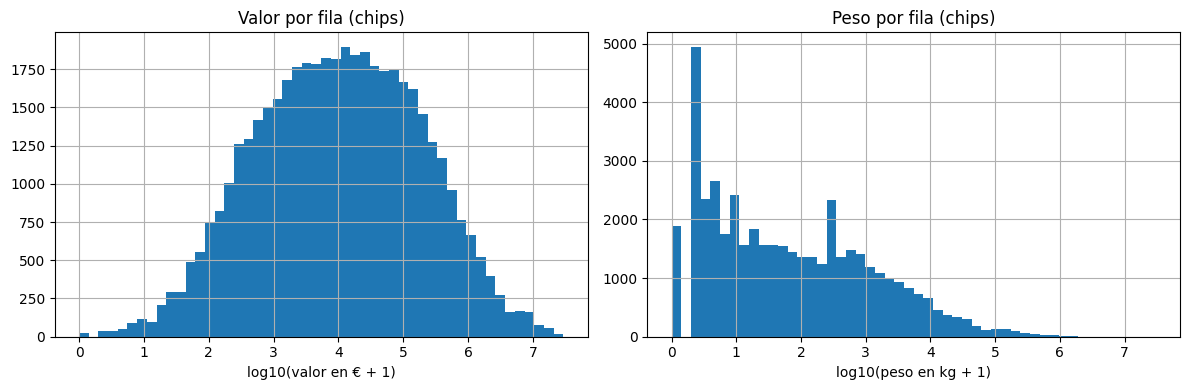

In [27]:
# Histogramas de valor y peso en escala logarítmica (log10), solo bloque chips.
# Sin escala log no se ve nada: hay filas de pocos euros y otras de millones.
# Se suma 1 para poder incluir los ceros (log10(0) no existe). Eje x: 1 = 10, 3 = 1,000, 6 = 1 millón.

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
np.log10(chips["valor_eur"] + 1).hist(bins=50, ax=ejes[0])
ejes[0].set_title("Valor por fila (chips)")
ejes[0].set_xlabel("log10(valor en € + 1)")
np.log10(chips["peso_kg"] + 1).hist(bins=50, ax=ejes[1])
ejes[1].set_title("Peso por fila (chips)")
ejes[1].set_xlabel("log10(peso en kg + 1)")
plt.tight_layout()
plt.show()

In [28]:
# ¿Qué pesos se repiten más? (un pico aislado puede indicar un peso declarado por defecto)
chips["peso_kg"].value_counts().head(10)

peso_kg
1.00     4944
2.00     2345
0.00     1888
3.00     1502
4.00     1148
5.00      971
6.00      773
7.00      668
8.00      601
10.00     588
Name: count, dtype: int64

In [29]:
# Filas de chips con 300–310 kg: ¿en qué años se concentran?
chips[chips["peso_kg"].between(300, 310)]["periodo"].str[:4].value_counts().sort_index()

periodo
2015     15
2016     16
2017      9
2018     11
2019     16
2020     17
2021     11
2022     12
2023    430
2024    466
2025     11
2026      9
Name: count, dtype: int64

**📌Conclusión:**
- Valor y peso muy asimétricos: la media es 44 veces la mediana en valor y unas 1,600 veces en peso (todas las filas). Se usarán la mediana en los resúmenes y pruebas no paramétricas.
- Los máximos de valor y de peso son todos paneles fotovoltaicos de China (854143) de 2022: envíos reales, no errores. Confirma la decisión de analizar la familia 854140 aparte.
- Solo chips: mediana de 10,542 € y 42 kg por fila. En escala logarítmica el valor sigue una distribución log-normal.
- Posibles errores en el peso: 17 filas de chips con más de 100,000 kg y un €/kg inferior al 1 % de lo normal de su código. Todas con socios de la UE (Intrastat). Suman cerca del 16 % de los kg de chips y el 0.1 % del valor. 7 son casos fuertes (por debajo del percentil 1 % de su código); el principal es Alemania, 854130, 2024-12, con 30.4 millones de kg a 0.14 €/kg.
- El peso tiene poca precisión en envíos pequeños (mínimo 1 kg; los pesos más repetidos son 1 a 10 kg).
- Acumulación de filas con 300–310 kg en 2023 y 2024 (896 de 1,023): posible cambio en cómo se declara o estima el peso. Impacto despreciable en los kg totales.

→ Limpieza: marcar con una bandera las filas con peso anómalo y excluirlas de la serie de kg (el valor se mantiene); marcar las filas con peso 0 o valor 0 y calcular el €/kg solo con las filas válidas; anotar como limitaciones la poca precisión del peso y el pico de 300 kg en 2023–2024.
---

## ✅Paso 5. Peso de cada código
**Enunciado:** Calcular qué parte del total en kg y en € representa cada código.

In [30]:
# Peso de cada código en el total de kg y de € (ES import, sin agregados, 2015-2026)
por_codigo = d.groupby("product")[["valor_eur", "peso_kg"]].sum()
por_codigo["% valor"] = por_codigo["valor_eur"] / por_codigo["valor_eur"].sum() * 100
por_codigo["% peso"] = por_codigo["peso_kg"] / por_codigo["peso_kg"].sum() * 100
por_codigo = por_codigo.join(prod.set_index("codigo")["descripcion"].str[:40])  # descripción corta
por_codigo.sort_values("% valor", ascending=False)

,valor_eur,peso_kg,% valor,% peso,descripcion
product,,,,,
854143,"9,741,592,854.00","3,091,587,651.00",35.53,67.25,Photovoltaic cells assembled in modules
854231,"4,734,110,869.00","50,646,826.00",17.27,1.10,Electronic integrated circuits as proces
854140,"4,728,339,671.00","1,129,943,324.00",17.25,24.58,"Photosensitive semiconductor devices, in"
854239,"3,838,673,380.00","51,621,302.00",14.00,1.12,Electronic integrated circuits (excl. su
854129,"1,077,115,309.00","37,846,733.00",3.93,0.82,Transistors with a dissipation rate >= 1
854232,"514,904,602.00","6,120,143.00",1.88,0.13,Electronic integrated circuits as memori
854149,"457,869,751.00","66,142,210.00",1.67,1.44,Photosensitive semiconductor devices (ex
854110,"452,232,305.00","24,376,007.00",1.65,0.53,Diodes (excl. photosensitive or light em
854141,"339,751,836.00","9,112,841.00",1.24,0.20,"Light emitting diodes ""LED"""


In [31]:
# Lo mismo por bloque: chips frente a optoelectrónica y fotovoltaica (familia 854140)
d["bloque"] = np.where(d["product"].isin(FAMILIA_FV), "optoelectronica_fv", "chips")
por_bloque = d.groupby("bloque")[["valor_eur", "peso_kg"]].sum()
por_bloque["% valor"] = por_bloque["valor_eur"] / por_bloque["valor_eur"].sum() * 100
por_bloque["% peso"] = por_bloque["peso_kg"] / por_bloque["peso_kg"].sum() * 100
por_bloque

,valor_eur,peso_kg,% valor,% peso
bloque,,,,
chips,"11,975,549,251.00","273,605,864.00",43.68,5.95
optoelectronica_fv,"15,441,264,698.00","4,323,283,557.00",56.32,94.05


**📌Conclusión:**
- La familia 854140 (fotovoltaica, LED y otros fotosensibles) es el 56.3 % del valor y el 94.1 % de los kg importados de 8541+8542 (2015-2026). Los chips son el 43.7 % del valor y el 5.9 % de los kg.
- Los paneles fotovoltaicos (854143) son el código principal: 35.5 % del valor y 67.3 % de los kg.
- Los circuitos integrados (8542) suman el 35 % del valor con solo el 2.5 % de los kg; destacan los procesadores (854231, 17.3 %) y otros circuitos integrados (854239, 14.0 %).
- Los kg de los dos bloques no son comparables: confirma la decisión de analizar la fotovoltaica aparte.
- En los tiristores (854130), unas tres cuartas partes de los kg vienen de una sola fila anómala (Alemania, 2024-12).

→ Limpieza: crear la columna `bloque` y tratar el peso anómalo antes de usar los kg de chips por código.

---

## ✅Paso 6. Evolución temporal
**Enunciado:** Representar los kg y el valor mensuales de cada bloque (chips y optoelectrónica/FV) para ver la tendencia, los huecos, los picos y la estacionalidad.

In [32]:
# Totales mensuales de valor y peso por bloque (ES import, sin agregados)
mensual = d.groupby(["periodo", "bloque"])[["valor_eur", "peso_kg"]].sum().unstack("bloque")
mensual.index = pd.to_datetime(mensual.index)          # "2015-01" → fecha, para que el eje x sea temporal
print("meses:", len(mensual))                          # deben ser 140 (2015-01 a 2026-08)
mensual.head()

meses: 140


valor_eur                         peso_kg                   
bloque             chips optoelectronica_fv        chips optoelectronica_fv
periodo                                                                    
2015-01-01 54,289,034.00       7,567,909.00 1,318,692.00         385,187.00
2015-02-01 60,544,470.00       7,765,771.00 2,582,296.00         479,907.00
2015-03-01 55,232,820.00       7,771,847.00 1,234,603.00         567,780.00
2015-04-01 65,054,000.00       8,354,663.00   840,537.00         583,011.00
2015-05-01 56,437,314.00       9,246,765.00 1,047,661.00         615,422.00

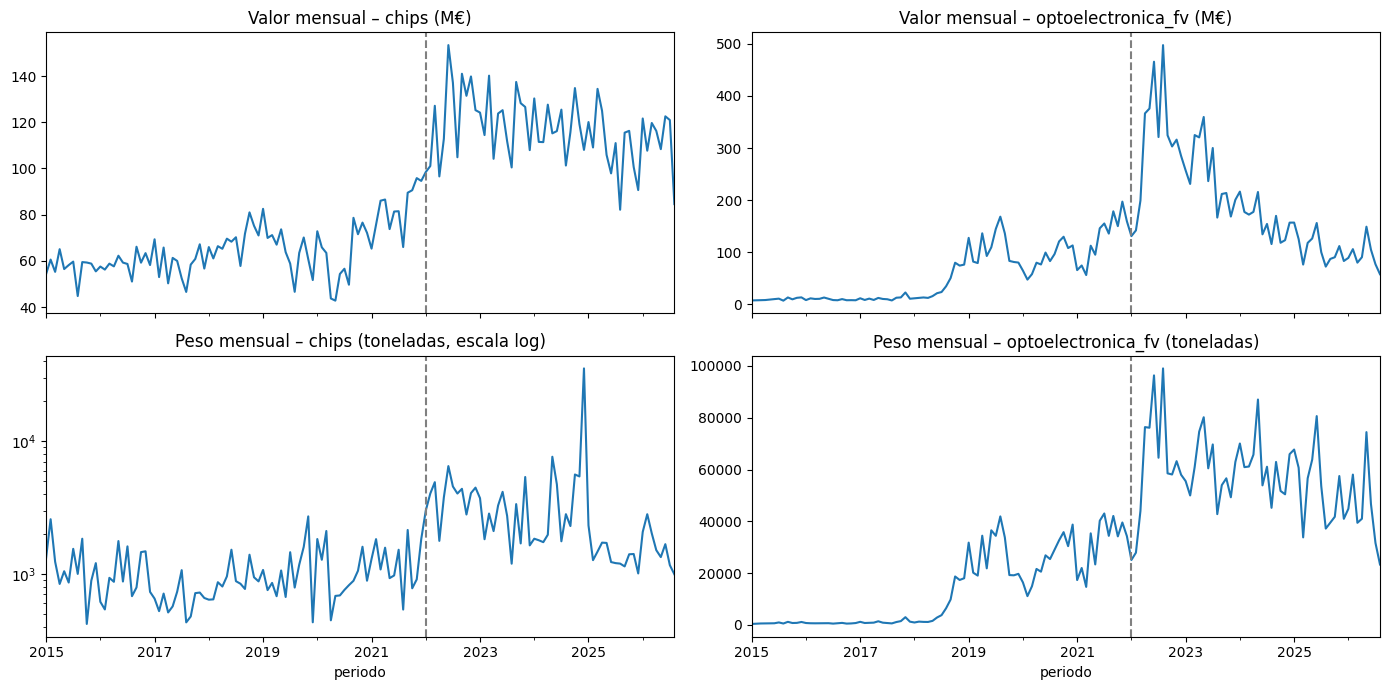

In [33]:
# Gráfico 2 × 2: valor (M€) y peso (toneladas), cada bloque por separado (la FV es tan grande que taparía a los chips).
# El peso de chips va en escala logarítmica: el pico de 2024-12 (fila anómala de Alemania) aplastaría el resto de la serie.
fig, ejes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)

for col, bloque in enumerate(["chips", "optoelectronica_fv"]):
    (mensual["valor_eur"][bloque] / 1e6).plot(ax=ejes[0, col], title=f"Valor mensual – {bloque} (M€)")
    (mensual["peso_kg"][bloque] / 1e3).plot(ax=ejes[1, col], title=f"Peso mensual – {bloque} (toneladas)")
    for fila in (0, 1):
        ejes[fila, col].axvline(pd.Timestamp("2022-01-01"), color="grey", linestyle="--")  # cambio de nomenclatura SA 2022

ejes[1, 0].set_yscale("log")                      # escala log solo en el peso de chips
ejes[1, 0].set_title("Peso mensual – chips (toneladas, escala log)")
# Alternativa a la escala log: ejes[1, 0].set_ylim(0, 8000)   # limitar el eje a 8,000 t; el pico se sale por arriba

plt.tight_layout()
plt.show()

**📌Conclusión:**
- 140 meses por bloque, sin huecos.
- Chips (valor): estable en unos 700–800 M€/año en 2015–2020; la subida empieza en 2020–2021 y en 2022 hay un salto de nivel (unos 1,470 M€) que se mantiene en 2023–2024. Coincide con la escasez de chips y la inflación, antes de cualquier efecto del PERTE. Valores en euros corrientes: parte del salto puede ser precio.
- Estacionalidad en chips: agosto un 19 % por debajo de la media anual; septiembre–noviembre un 7–9 % por encima.
- Chips (peso): picos aislados en diciembre de 2024 (35,000 t, unas 28 veces la mediana mensual) y mayo de 2024, causados por las filas con peso anómalo del paso 4. El pico de diciembre de 2024 impide ver el resto de la serie, por eso se muestra en escala logarítmica.
- A simple vista (peso en escala log), el valor y el peso de chips evolucionan de forma parecida, sobre todo por la tendencia común de 2021–2022. Se deja como observación visual; la correlación formal entre valor y kg queda fuera del planteamiento final.
- Fotovoltaica: el crecimiento arranca a finales de 2018 y llega al máximo en 2022 (3,728 M€); después el valor cae mientras los kg siguen altos, por la bajada del precio de los paneles.
- Sin salto en enero de 2022 por el cambio de nomenclatura.

→ Limpieza y análisis: tratar el peso anómalo; usar modelos con estacionalidad.

---

## ✅Paso 7. Principales socios
**Enunciado:** Identificar los principales países proveedores de España por valor y por peso, en cada bloque (chips y optoelectrónica/FV).

In [34]:
# Principales proveedores de chips por valor (ES import, sin agregados, 2015-2026), con su cuota en valor y en peso
chips = d[d["bloque"] == "chips"]
socios = chips.groupby("partner")[["valor_eur", "peso_kg"]].sum()
socios["% valor"] = socios["valor_eur"] / socios["valor_eur"].sum() * 100
socios["% peso"] = socios["peso_kg"] / socios["peso_kg"].sum() * 100
socios = socios.join(soc.set_index("codigo")["nombre"])          # nombre del país
socios.sort_values("% valor", ascending=False).head(10)

,valor_eur,peso_kg,% valor,% peso,nombre
partner,,,,,
DE,"4,524,517,972.00","148,574,395.00",37.78,54.30,Germany (incl. German Democratic Republic 'DD'...
NL,"1,834,253,241.00","25,156,679.00",15.32,9.19,Netherlands
CN,"813,716,835.00","19,852,700.00",6.79,7.26,China
JP,"793,659,014.00","4,861,369.00",6.63,1.78,Japan
FR,"608,338,584.00","18,484,737.00",5.08,6.76,France (incl. Saint Barthélemy 'BL' -> 2012; i...
CZ,"435,479,840.00","6,417,816.00",3.64,2.35,Czechia
US,"395,542,219.00","543,403.00",3.30,0.20,United States (incl. Navassa Island (part of '...
GB,"369,717,461.00","4,692,699.00",3.09,1.72,United Kingdom
BE,"317,940,873.00","2,918,560.00",2.65,1.07,Belgium (incl. Luxembourg 'LU' -> 1998)


In [35]:
# Lo mismo para el bloque de optoelectrónica y fotovoltaica
fv = d[d["bloque"] == "optoelectronica_fv"]
socios_fv = fv.groupby("partner")[["valor_eur", "peso_kg"]].sum()
socios_fv["% valor"] = socios_fv["valor_eur"] / socios_fv["valor_eur"].sum() * 100
socios_fv["% peso"] = socios_fv["peso_kg"] / socios_fv["peso_kg"].sum() * 100
socios_fv = socios_fv.join(soc.set_index("codigo")["nombre"])
socios_fv.sort_values("% valor", ascending=False).head(10)

,valor_eur,peso_kg,% valor,% peso,nombre
partner,,,,,
CN,"10,200,916,484.00","3,102,433,546.00",66.06,71.76,China
PT,"1,523,464,461.00","474,892,226.00",9.87,10.98,Portugal
DE,"1,459,076,298.00","279,493,308.00",9.45,6.46,Germany (incl. German Democratic Republic 'DD'...
NL,"979,669,938.00","196,964,669.00",6.34,4.56,Netherlands
FR,"183,655,860.00","55,114,963.00",1.19,1.27,France (incl. Saint Barthélemy 'BL' -> 2012; i...
DK,"167,363,849.00","54,077,308.00",1.08,1.25,Denmark
MY,"147,300,517.00","33,672,516.00",0.95,0.78,Malaysia
JP,"138,784,039.00","564,283.00",0.90,0.01,Japan
VN,"108,223,023.00","32,622,943.00",0.70,0.75,Viet Nam (incl. North Viet Nam 'VD' from 1977)


In [36]:
# Origen real de los chips: importaciones de la UE27 desde países de fuera de la UE (2015-2026).
# Para los socios extra-UE, Comext registra el país de ORIGEN (dónde se fabricó), no el de expedición.
UE27 = {"AT", "BE", "BG", "CY", "CZ", "DE", "DK", "EE", "ES", "FI", "FR", "GR", "EL", "HR", "HU",
        "IE", "IT", "LT", "LU", "LV", "MT", "NL", "PL", "PT", "RO", "SE", "SI", "SK"}   # Grecia puede venir como GR o EL

ue_extra = ue[(ue["partner"].map(tipo_socio) == "país") & (~ue["partner"].isin(UE27))].copy()
ue_extra["bloque"] = np.where(ue_extra["product"].isin(FAMILIA_FV), "optoelectronica_fv", "chips")
chips_ue = ue_extra[ue_extra["bloque"] == "chips"]

origen = chips_ue.groupby("partner")[["valor_eur", "peso_kg"]].sum()
origen["% valor"] = origen["valor_eur"] / origen["valor_eur"].sum() * 100
origen["% peso"] = origen["peso_kg"] / origen["peso_kg"].sum() * 100
origen = origen.join(soc.set_index("codigo")["nombre"])
origen.sort_values("% valor", ascending=False).head(10)

,valor_eur,peso_kg,% valor,% peso,nombre
partner,,,,,
TW,"84,043,394,271.00","48,586,300.00",19.42,6.15,Taiwan
MY,"76,789,495,245.00","67,003,789.00",17.74,8.48,Malaysia
CN,"60,722,156,285.00","334,257,211.00",14.03,42.32,China
US,"34,542,692,740.00","17,529,933.00",7.98,2.22,United States (incl. Navassa Island (part of '...
KR,"30,290,857,452.00","18,886,389.00",7.00,2.39,"Korea, Republic of (South Korea)"
PH,"24,607,094,447.00","28,586,061.00",5.69,3.62,Philippines
IL,"20,710,170,702.00","1,418,842.00",4.79,0.18,Israel (incl. West Bank and Gaza Strip 'XP' ->...
JP,"20,186,571,277.00","34,838,993.00",4.66,4.41,Japan
TH,"18,493,410,980.00","19,451,133.00",4.27,2.46,Thailand


**📌Conclusión:**
- Chips (España): Alemania (37.8 %) y Países Bajos (15.3 %) suman el 53 % del valor importado; con China, los tres primeros llegan al 59.9 %. Siete de los diez primeros socios son europeos y no aparecen Taiwán, Corea del Sur ni Malasia.
- Para los socios de la UE, Comext registra el país de expedición, no el de fabricación: Alemania y Países Bajos actúan como centros de distribución. Con los datos de España se mide la concentración de proveedores inmediatos, no el origen real.
- Origen real (importaciones de chips de la UE desde fuera de la UE): Taiwán (19.4 %), Malasia (17.7 %) y China (14.0 %) suman el 51.2 % del valor; los siete países asiáticos del top 10 llegan al 72.8 %.
- En peso, China (42.3 % de los kg) y Reino Unido (18.9 %) pesan mucho más que en valor: productos más baratos o posible peso anómalo, a revisar.
- Fotovoltaica (España, solo descriptivo): China es el 66.1 % del valor y el 71.8 % de los kg; le siguen Portugal, Alemania y Países Bajos (85.4 % entre los tres primeros).

→ Análisis: el origen real de España se mide con Datacomex (paso 8); el HHI (resultado 1) se calcula por país de origen, y Comext se usa como comparación (expedición).
---

## ✅Paso 8. Datacomex: importaciones de España por país de origen
**Enunciado:** Explorar la descarga mensual de Datacomex (API, 11 nov 2026), que da las importaciones de España por **país de origen**, y comprobar que es coherente con Comext antes de usarla como fuente principal del resultado 1.

In [37]:
# Datacomex (API): importaciones de España por país de origen, 19 códigos HS6, mensual 2015-2026.
# Se lee como texto, igual que Comext, para no alterar códigos ni decimales.
dc = pd.read_csv(RAW / "datacomex_api_import_origen_mensual.csv", dtype=str, keep_default_na=False)
print(dc.shape)
print(dc[["flujo", "prov", "mensaje"]].apply(lambda s: s.unique()))
dc.head()

(56947, 10)
flujo                            [Importación]
prov                          [Total Nacional]
mensaje    [dato definitivo, dato provisional]
dtype: object


,flujo,periodo,pais,id_pais,prov,id_prov,taric,euros,kilos,mensaje
0,Importación,Enero de 2015,Francia,001,Total Nacional,0,854110,"31382,39","4221,461",dato definitivo
1,Importación,Febrero de 2015,Francia,001,Total Nacional,0,854110,"14714,32","308,692",dato definitivo
2,Importación,Marzo de 2015,Francia,001,Total Nacional,0,854110,"18754,2","352,796",dato definitivo
3,Importación,Abril de 2015,Francia,001,Total Nacional,0,854110,"16108,59","114,666",dato definitivo
4,Importación,Mayo de 2015,Francia,001,Total Nacional,0,854110,"39018,34","249,425",dato definitivo


In [38]:
# Columnas auxiliares para explorar (las originales no se tocan):
# euros y kilos vienen como texto con coma decimal ("1942085,7") → número;
# periodo viene como texto ("Enero de 2015") → fecha del primer día del mes.
meses = {"Enero": 1, "Febrero": 2, "Marzo": 3, "Abril": 4, "Mayo": 5, "Junio": 6, "Julio": 7,
         "Agosto": 8, "Septiembre": 9, "Octubre": 10, "Noviembre": 11, "Diciembre": 12}
dc["valor_eur"] = pd.to_numeric(dc["euros"].str.replace(",", ".", regex=False))
dc["peso_kg"] = pd.to_numeric(dc["kilos"].str.replace(",", ".", regex=False))
mes_anio = dc["periodo"].str.split(" de ", expand=True)
dc["fecha"] = pd.to_datetime(dict(year=mes_anio[1].astype(int), month=mes_anio[0].map(meses), day=1))
print("Periodo:", dc["fecha"].min().date(), "→", dc["fecha"].max().date(), "|", dc["fecha"].nunique(), "meses")

Periodo: 2015-01-01 → 2026-08-01 | 140 meses


In [39]:
# Vacíos, duplicados por la clave (mes × país × código), ceros y datos provisionales
print("Vacíos por columna:", (dc == "").sum().to_dict())
print("Duplicados (periodo, id_pais, taric):", dc.duplicated(["periodo", "id_pais", "taric"]).sum())
print("Filas con valor 0:", (dc["valor_eur"] == 0).sum(), "| con peso 0:", (dc["peso_kg"] == 0).sum())
print(dc["mensaje"].value_counts())
print("Último mes definitivo:", dc.loc[dc["mensaje"] == "dato definitivo", "fecha"].max().date())

Vacíos por columna: {'flujo': 0, 'periodo': 0, 'pais': 0, 'id_pais': 0, 'prov': 0, 'id_prov': 0, 'taric': 0, 'euros': 0, 'kilos': 0, 'mensaje': 0, 'valor_eur': 0, 'peso_kg': 0, 'fecha': 0}
Duplicados (periodo, id_pais, taric): 0
Filas con valor 0: 0 | con peso 0: 0
mensaje
dato definitivo     42372
dato provisional    14575
Name: count, dtype: int64
Último mes definitivo: 2023-12-01


In [40]:
# Países: cuántos hay y cuáles son códigos especiales (no son países reales)
print("Países distintos:", dc["id_pais"].nunique())
paises = dc[["id_pais", "pais"]].drop_duplicates().sort_values("id_pais")
paises[paises["id_pais"].astype(int) >= 950]

Países distintos: 200


,id_pais,pais
38530,952,Avituallamiento terceros
7609,958,Países y
375,959,Países y
35712,960,Países y


In [41]:
# Cobertura de códigos por año: el cambio de nomenclatura de 2022 debe verse igual que en Comext
dc["anio"] = dc["fecha"].dt.year
dc.pivot_table(index="taric", columns="anio", values="valor_eur", aggfunc="size", fill_value=0)

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
taric,,,,,,,,,,,,
854110,387,378,394,381,370,371,395,407,424,426,416,287
854121,225,223,235,230,210,189,223,243,220,207,239,170
854129,375,376,380,344,360,335,368,381,380,385,399,266
854130,214,213,225,211,221,219,230,237,260,261,266,178
854140,514,522,530,519,508,503,549,0,0,0,0,0
854141,0,0,0,0,0,0,0,373,351,367,371,241
854142,0,0,0,0,0,0,0,128,112,109,85,57
854143,0,0,0,0,0,0,0,209,237,252,261,168
854149,0,0,0,0,0,0,0,407,396,377,373,245


In [42]:
# ¿Cuadra Datacomex con Comext? Total anual de chips (sin la familia FV) en millones de €
dc["bloque"] = np.where(dc["taric"].isin(FAMILIA_FV), "optoelectronica_fv", "chips")
comext_chips = es[(es["partner"].map(tipo_socio) != "agregado") & (~es["product"].isin(FAMILIA_FV))]
comparacion = pd.DataFrame({
    "datacomex_M€": dc[dc["bloque"] == "chips"].groupby("anio")["valor_eur"].sum() / 1e6,
    "comext_M€": comext_chips.groupby(comext_chips["periodo"].str[:4].astype(int))["valor_eur"].sum() / 1e6})
comparacion["diferencia_%"] = (comparacion["datacomex_M€"] / comparacion["comext_M€"] - 1) * 100
comparacion

,datacomex_M€,comext_M€,diferencia_%
2015,687.11,687.10,0.00
2016,708.10,708.09,0.00
2017,701.51,701.49,0.00
2018,823.08,823.43,-0.04
2019,778.87,779.37,-0.06
2020,747.43,747.96,-0.07
2021,986.13,986.75,-0.06
2022,"1,468.58","1,469.20",-0.04
2023,"1,444.04","1,444.75",-0.05
2024,"1,410.55","1,416.88",-0.45


In [43]:
# Origen (Datacomex) frente a expedición (Comext): cuota de los principales países en el valor de chips, 2015-2026
cuota_origen = dc[dc["bloque"] == "chips"].groupby("pais")["valor_eur"].sum()
cuota_origen = (cuota_origen / cuota_origen.sum() * 100).sort_values(ascending=False)
cuota_expedicion = comext_chips.groupby("partner")["valor_eur"].sum()
cuota_expedicion = cuota_expedicion / cuota_expedicion.sum() * 100
pares = {"Alemania": "DE", "Países Bajos": "NL", "China": "CN", "Japón": "JP", "Estados Unidos": "US",
         "Taiwán": "TW", "Malasia": "MY", "Francia": "FR"}
pd.DataFrame({"% origen (Datacomex)": cuota_origen.reindex(pares.keys()),
              "% expedición (Comext)": [cuota_expedicion.get(c, 0) for c in pares.values()]})

,% origen (Datacomex),% expedición (Comext)
pais,,
Alemania,26.67,37.78
Países Bajos,14.65,15.32
China,14.01,6.79
Japón,7.87,6.63
Estados Unidos,5.67,3.30
Taiwán,4.30,1.78
Malasia,3.90,1.30
Francia,3.53,5.08


**📌Conclusión:**
- **Datos completos y limpios en origen:** 56,947 filas (mes × país de origen × código), de enero de 2015 a agosto de 2026 (140 meses), 200 países y los 19 códigos. Sin vacíos, sin duplicados y sin filas con valor o peso 0.
- **Formato:** euros y kilos vienen como texto con coma decimal y el periodo como texto ("Enero de 2015"): hay que convertirlos en la limpieza. La API corta los nombres largos de país, así que se trabajará con `id_pais`.
- **Códigos especiales:** 952 (avituallamiento) y 958–960 (países y territorios no determinados) no son países reales: se clasificarán como en Comext.
- **Datos provisionales:** unas 14,600 filas (los meses más recientes) son provisionales; se mantienen y se marcan con una bandera.
- **Cambio de nomenclatura de 2022:** se ve igual que en Comext (854140 y 854150 hasta 2021; sus sustitutos desde 2022).
- **Coherencia con Comext:** los totales anuales de chips coinciden (diferencias < 1 %), así que es la misma fuente con más detalle.
- **Hallazgo: origen frente a expedición.** Por país de origen, China pasa del 6.79 % al 14.01 % del valor de chips, y Taiwán y Malasia se duplican o triplican; Alemania baja del 37.78 % al 26.67 %. Parte de lo que Comext atribuye a Alemania o Países Bajos se fabricó en Asia: la dependencia asiática es mayor de lo que muestra la expedición.
- **Limitación:** Alemania y Países Bajos siguen pesando mucho también por origen. Puede ser fabricación real o que en el comercio dentro de la UE el origen no siempre se declare; se explicará en la Metodología.
- **Decisión:** Datacomex será la fuente principal para el resultado 1 (concentración y origen); Comext, la comprobación.

## ✅Paso 9. Resumen de la exploración y tareas de limpieza
**Enunciado:** Resumir los hallazgos de la exploración y traducirlos en tareas para la fase de limpieza.

### 9.1 Hallazgos principales
| Paso | Hallazgo | Consecuencia |
|---|---|---|
| 0–1 | Comext: sin duplicados ni nulos; `SUPPLEMENTARY_QUANTITY` vacía al 100 %; filas con peso 0 (envíos < 0.5 kg) o valor 0 (< 0.1 % del valor) | El kg es la única medida de cantidad; banderas para peso 0 y valor 0 |
| 2 | Los agregados (`WORLD`, `EXT_*`, `INT_*`) son el 26 % de las filas de España; la suma de países coincide al euro con `WORLD` | Separar los agregados en una tabla aparte para no contar dos veces |
| 3 | Cambio de nomenclatura en 2022-01 (854140 y 854150 se dividen); sin salto real al armonizar | Familias armonizadas para series largas |
| 4–5 | Fotovoltaica y LED = 56 % del valor y 94 % de los kg; 17 filas de chips con peso mal declarado (≈ 16 % de los kg, 0.1 % del valor), todas intra-UE | Analizar chips aparte (`bloque`); bandera de peso anómalo |
| 6 | Chips: ~700–800 M€/año hasta 2020, salto a ~1,450 M€ en 2022; agosto ~19 % por debajo de la media | Modelos con estacionalidad; valores en euros corrientes |
| 7 | Por expedición (Comext), Alemania + Países Bajos ≈ 53 % del valor de chips; en la UE, el origen extra-UE es 73 % asiático | El país de expedición esconde el origen real |
| 8 | Datacomex por **origen** cuadra con Comext (< 1 %); China pasa del 6.79 % al 14.01 %, Taiwán y Malasia se duplican o triplican, Alemania baja del 37.78 % al 26.67 %; peso con precisión de gramos y sin el error de 2024-12 | **Datacomex = fuente principal del proyecto**, también para la serie de kg de la previsión.

### 9.2 Tareas de limpieza
**Criterio general:** no se elimina ninguna fila ni se inventan datos. Las filas que no son países (agregados) se separan en una tabla aparte.

**Comext**
1. **Separar los agregados** de socios (`WORLD`, `EXT_*`, `INT_*`) en una tabla aparte, que se usa para validar totales; no se elimina ninguna fila.
2. **Clasificar los socios**: país, territorio (Ceuta y Melilla) y no especificado (`QP`, `QQ`–`QZ`, fuera del HHI).
3. **Eliminar `SUPPLEMENTARY_QUANTITY`** (vacía al 100 %).
4. **Tipos y unidades**: `valor_eur` (float), `peso_kg` = `QUANTITY_IN_100KG` × 100 y `periodo` a fecha.

**Datacomex**

5. **Tipos y unidades**: `euros` y `kilos` a número (coma decimal) como `valor_eur` y `peso_kg`; `periodo` ("Enero de 2015") a fecha.
6. **Clasificar los países**: 952 (avituallamiento) y 958–960 (no determinados) como "no especificado" (fuera del HHI); trabajar con `id_pais`, porque la API corta los nombres.
7. **Columna de región de origen**: UE / terceros países, y dentro de terceros, Asia / resto.
8. **Bandera `dato_provisional`** a partir de `mensaje` (2024–2026); las filas se mantienen.

**Comunes a Comext y Datacomex**

9. **Armonizar los códigos** del cambio de 2022 (familias 854140 y 854150) y **crear la columna `bloque`**: chips / optoelectrónica y FV.
10. **Bandera de peso anómalo** en chips: la fila se mantiene en la tabla y en los totales de valor; solo su peso no se suma en la serie de kg.
11. **Banderas de peso 0 y valor 0** y **€/kg solo con las filas válidas**; todas las filas se mantienen en los totales.

**TIO y guardado**

12. **TIO 2022**: usar la fila de números de rama como código de cada sector (no es un dato), quitar las columnas vacías (`Unnamed`) y poner los nombres de los sectores (Tabla 8).
13. **Guardar las tablas limpias** (Comext, Datacomex y TIO) en `datos/procesados`, sin tocar `raw`.

### 9.3 Limitaciones para el informe
- kg ruidoso en envíos pequeños y pico de 300 kg en 2023–2024 (Comext).
- Expedición frente a origen: resuelto en parte con Datacomex; Alemania y Países Bajos siguen pesando mucho también por origen (falta verificar cómo se asigna el origen en el comercio intra-UE).
- Datos provisionales de 2024–2026 en Datacomex.
- Valores en euros corrientes (sin deflactar).
- Periodo: la exploración describe todos los datos (2015-01 a 2026-08); el análisis usa años completos 2015–2025 y 2026 solo se usa para comprobar la previsión.